# Khám phá Dữ liệu (EDA) - R2AI Stage 3

Notebook này phân tích danh sách URL và tập câu hỏi từ dataset chính thức của BTC (AIGuruTinix/ViBioMIR).

In [182]:
import pandas as pd
import pyarrow.parquet as pq
from urllib.parse import urlparse
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

## 1. Load Dữ liệu từ Parquet

In [183]:
df_queries = pq.read_table('../data/raw/btc_provided/query.parquet').to_pandas()
print(f"Tổng số câu hỏi: {len(df_queries)}")
display(df_queries.head())

df_corpus = pq.read_table('../data/raw/btc_provided/links_corpus.parquet').to_pandas()
print(f"Tổng số URLs: {len(df_corpus):,}")
display(df_corpus.head())

Tổng số câu hỏi: 1200


,id,query
0,1,"Em bị viêm xung huyết 1/3 dưới thực quản, viêm..."
1,2,"Răng có lỗ chấm đen, chảy máu khi thức dậy là ..."
2,3,Kết quả của Beta-HCG là dưới 0.10 U/L thì là n...
3,4,Chỉ số SCC của em sau khi xét nghiệm là 1.52 v...
4,5,Cách phòng tránh nguy cơ lây nhiễm bệnh lao đa...


Tổng số URLs: 4,394,718


,id,url
0,583,http://special.vietnamplus.vn/benh_vien_nhan_ai
1,584,https://bachmai.gov.vn/bai-viet/-nguoi-dan-se-...
2,585,https://bachmai.gov.vn/bai-viet/-roi-loan-su-t...
3,586,https://bachmai.gov.vn/bai-viet/1-4-nguoi-truo...
4,587,https://bachmai.gov.vn/bai-viet/1-5-phai-manh-...


## 2. Phân tích phân phối Domain (Tiếng Việt & Tiếng Trung)
Biết chính xác dữ liệu đến từ những domain nào giúp cấu hình BeautifulSoup/XPath bóc tách HTML chính xác (loại bỏ quảng cáo, header, footer).

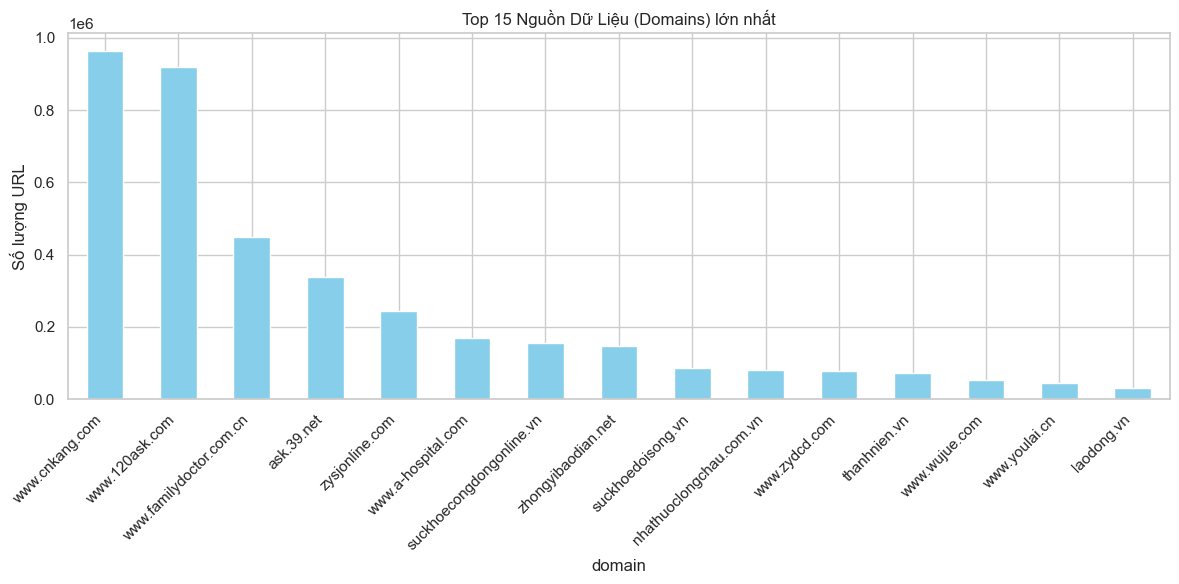

Thống kê chi tiết top 15:
domain
www.cnkang.com              963438
www.120ask.com              918479
www.familydoctor.com.cn     447453
ask.39.net                  337375
zysjonline.com              243347
www.a-hospital.com          169339
suckhoecongdongonline.vn    154503
zhongyibaodian.net          146700
suckhoedoisong.vn            85823
nhathuoclongchau.com.vn      79598
www.zydcd.com                78680
thanhnien.vn                 72111
www.wujue.com                53341
www.youlai.cn                46119
laodong.vn                   31282
Name: count, dtype: int64


In [184]:
def extract_domain(url):
    try:
        return urlparse(url).netloc
    except:
        return None

df_corpus['domain'] = df_corpus['url'].apply(extract_domain)

plt.figure(figsize=(12, 6))
top_domains = df_corpus['domain'].value_counts().head(15)
top_domains.plot(kind='bar', color='skyblue')
plt.title('Top 15 Nguồn Dữ Liệu (Domains) lớn nhất')
plt.ylabel('Số lượng URL')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Thống kê chi tiết top 15:")
print(top_domains)

## 3. Phân tích độ dài câu hỏi (Queries)


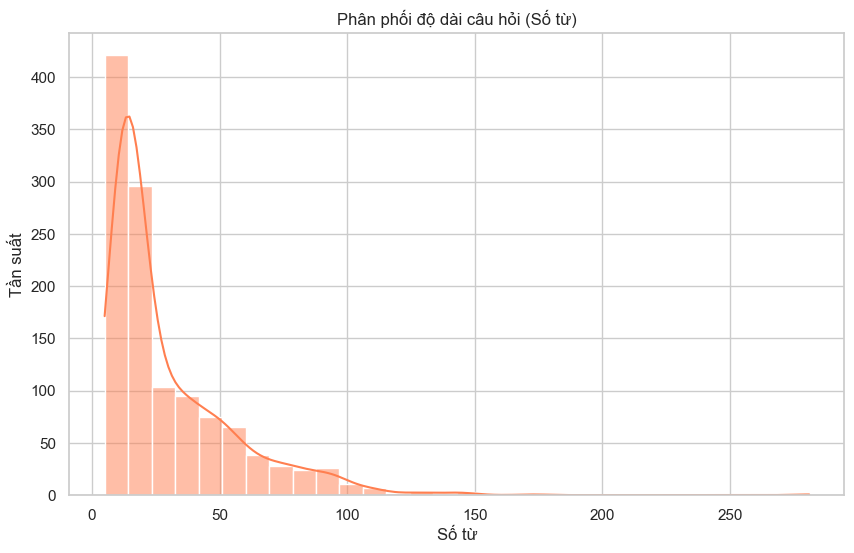

count    1200.000000
mean       29.910833
std        25.847881
min         5.000000
25%        13.000000
50%        18.000000
75%        40.000000
max       281.000000
Name: word_count, dtype: float64


In [185]:
df_queries['word_count'] = df_queries['query'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 6))
sns.histplot(df_queries['word_count'], bins=30, kde=True, color='coral')
plt.title('Phân phối độ dài câu hỏi (Số từ)')
plt.xlabel('Số từ')
plt.ylabel('Tần suất')
plt.show()

print(df_queries['word_count'].describe())

## 4. Phân tích độ dài văn bản (Sau khi Crawl)
Phần này sẽ được chạy sau khi chúng ta viết xong web scraper và crawl thử một phần nội dung.

In [186]:
# Code sẽ được thêm vào sau